# 02 · Pose on the full video

**Goal:** do what notebook 01 did, but on **every frame**, then stitch the frames back into a video so you can watch the skeleton move with you.

**The idea in plain English:** a video is a flipbook. Notebook 01 drew a skeleton on one page. This notebook flips through every page, draws a skeleton on each one, and staples the pages back together into a new video.

Along the way it also writes down every dot's position on every frame in a spreadsheet (CSV). That spreadsheet is what we'll use later to spot strokes.

Everything is filled in. Run each cell with **Shift + Enter**. The only things you might change are in the box marked *Things you can change*.

## Step 0 · Setup

In [16]:
import time
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import pandas as pd
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# ---- Things you can change ----
CLIP_FOLDER = PROJECT / "data" / "raw"
CLIP_NAME = "IMG_1188"
START_SEC = None        # e.g. 5 to skip the first 5 seconds; None = from the start
END_SEC = None          # e.g. 15 to stop at 15 seconds; None = to the end
MODEL_VARIANT = "full"  # "lite" (fast), "full", or "heavy" (slow, most accurate)
VIS_THRESHOLD = 0.5     # dots below this confidence are drawn red
FLIP_180 = True
# -------------------------------

VIDEO_PATH = sorted(CLIP_FOLDER.glob(CLIP_NAME + ".*"))[0]
OUT_DIR = PROJECT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

MODEL_PATH = PROJECT / "models" / f"pose_landmarker_{MODEL_VARIANT}.task"
if not MODEL_PATH.exists():
    MODEL_PATH.parent.mkdir(exist_ok=True)
    url = ("https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
           f"pose_landmarker_{MODEL_VARIANT}/float16/latest/pose_landmarker_{MODEL_VARIANT}.task")
    print("Downloading model...")
    urllib.request.urlretrieve(url, MODEL_PATH)

NAMES = [p.name.lower() for p in vision.PoseLandmark]
CONNECTIONS = vision.PoseLandmarksConnections.POSE_LANDMARKS
print("Video:", VIDEO_PATH.name, "| Model:", MODEL_PATH.name)

Video: IMG_1188.mov | Model: pose_landmarker_full.task


## Step 1 · The drawing function

This is your Step 6 + Step 7 code from notebook 01, packaged into a **function**: a reusable recipe with a name. Instead of copying the drawing code for every frame, we write it once here and call `draw_pose(...)` on each frame.

In [17]:
def draw_pose(image_rgb, landmarks):
    """Draw white skeleton lines, then green (confident) or red (unsure) dots."""
    h, w = image_rgb.shape[:2]
    for c in CONNECTIONS:
        a, b = landmarks[c.start], landmarks[c.end]
        cv2.line(image_rgb, (int(a.x * w), int(a.y * h)), (int(b.x * w), int(b.y * h)),
                 (255, 255, 255), 3)
    for lm in landmarks:
        colour = (0, 255, 0) if lm.visibility >= VIS_THRESHOLD else (255, 0, 0)
        cv2.circle(image_rgb, (int(lm.x * w), int(lm.y * h)), 8, colour, -1)
    return image_rgb

## Step 2 · Run it on every frame

This is the main loop. For each frame it:

1. reads the next photo from the video,
2. flips the colours from BGR to RGB (the gotcha from notebook 01),
3. asks MediaPipe for the 33 dots,
4. writes each dot's numbers into the spreadsheet,
5. draws the skeleton and adds the frame to the output video.

**One change from notebook 01:** we now use `VIDEO` mode instead of `IMAGE` mode. In video mode MediaPipe remembers where you were in the last frame, which makes it faster and steadier. It needs a timestamp for each frame so it knows the order.

This takes a minute or two. It prints progress as it goes.

In [18]:
cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
first = int(START_SEC * fps) if START_SEC else 0
last = min(int(END_SEC * fps), total) if END_SEC else total
cap.set(cv2.CAP_PROP_POS_FRAMES, first)

options = vision.PoseLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path=str(MODEL_PATH)),
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1,
)

OUT_VIDEO = OUT_DIR / f"pose_{CLIP_NAME}.mp4"
writer = None
rows = []
frames_done = 0
frames_found = 0
t0 = time.time()

with vision.PoseLandmarker.create_from_options(options) as landmarker:
    for frame_idx in range(first, last):
        ok, frame_bgr = cap.read()
        if not ok:
            break
        if FLIP_180:                                         # NEW: spin the frame upright
            frame_bgr = cv2.rotate(frame_bgr, cv2.ROTATE_180)
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

        if writer is None:
            h, w = frame_rgb.shape[:2]
            writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

        timestamp_ms = int(frame_idx * 1000 / fps)
        result = landmarker.detect_for_video(
            mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb), timestamp_ms)

        if result.pose_landmarks:
            frames_found += 1
            landmarks = result.pose_landmarks[0]
            for name, lm in zip(NAMES, landmarks):
                rows.append({"frame": frame_idx, "time_s": round(frame_idx / fps, 3), "point": name,
                             "x": lm.x, "y": lm.y, "visibility": lm.visibility})
            draw_pose(frame_rgb, landmarks)

        label = f"{frame_idx / fps:6.2f}s   frame {frame_idx}"   # time stamp box
        cv2.rectangle(frame_rgb, (20, 20), (560, 90), (0, 0, 0), -1)
        cv2.putText(frame_rgb, label, (35, 72), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (255, 255, 255), 3)

        writer.write(cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR))
        frames_done += 1
        if frames_done % 300 == 0:
            print(f"  {frames_done} frames done ({frame_idx / fps:.1f} s into the clip)")

cap.release()
writer.release()
seconds = time.time() - t0
print(f"Finished: {frames_done} frames in {seconds:.0f} s ({frames_done / seconds:.1f} frames per second)")

W0000 00:00:1792300951.539439 3479561 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792300951.566095 3479561 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  300 frames done (5.0 s into the clip)
  600 frames done (10.0 s into the clip)
  900 frames done (15.0 s into the clip)
  1200 frames done (20.0 s into the clip)
  1500 frames done (25.0 s into the clip)
Finished: 1713 frames in 62 s (27.7 frames per second)


## Step 3 · How did it do?

The headline number for task 1.15 is the **dropout rate**: the share of frames where MediaPipe couldn't find you at all. Low is good.

We also save the spreadsheet of every dot on every frame.

In [19]:
dropout = 1 - frames_found / frames_done
print(f"Frames processed:   {frames_done}")
print(f"Person found in:    {frames_found}")
print(f"Dropout rate:       {dropout:.1%}")

df = pd.DataFrame(rows)
OUT_CSV = OUT_DIR / f"pose_{CLIP_NAME}.csv"
df.to_csv(OUT_CSV, index=False)
print()
print("Video saved to:", OUT_VIDEO)
print("CSV saved to:  ", OUT_CSV, f"({len(df):,} rows)")
df.head(10)

Frames processed:   1713
Person found in:    1610
Dropout rate:       6.0%

Video saved to: /Users/kelechiejieke/Downloads/Programming/ai-tennis-coach/outputs/pose_IMG_1188.mp4
CSV saved to:   /Users/kelechiejieke/Downloads/Programming/ai-tennis-coach/outputs/pose_IMG_1188.csv (53,130 rows)


,frame,time_s,point,x,y,visibility
0,7,0.117,nose,0.509528,0.542204,0.996855
1,7,0.117,left_eye_inner,0.512002,0.546684,0.996643
2,7,0.117,left_eye,0.512559,0.545519,0.997274
3,7,0.117,left_eye_outer,0.513121,0.544225,0.996136
4,7,0.117,right_eye_inner,0.513668,0.548063,0.996648
5,7,0.117,right_eye,0.512272,0.549299,0.996605
6,7,0.117,right_eye_outer,0.512617,0.550006,0.995850
7,7,0.117,left_ear,0.517473,0.536449,0.994168
8,7,0.117,right_ear,0.516139,0.544669,0.991001
9,7,0.117,mouth_left,0.510837,0.533379,0.985763


## Step 4 · Peek at a few frames

Four evenly spaced frames from the output video, so you can check it worked without leaving the notebook.

**To watch the full video:** open the `outputs` folder in Finder and double-click `pose_IMG_1188.mp4`. If QuickTime refuses to play it, drag it into a Chrome tab or open it with VLC.

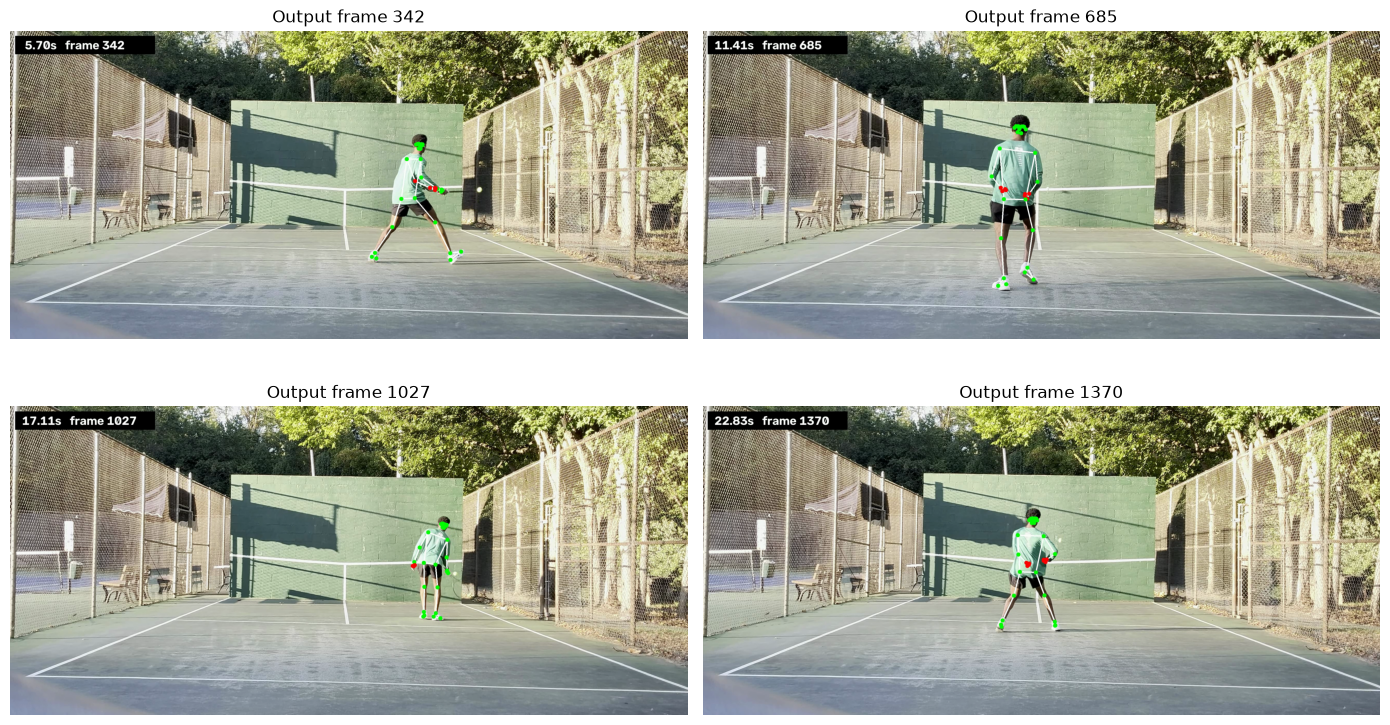

In [20]:
check = cv2.VideoCapture(str(OUT_VIDEO))
n = int(check.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, i in zip(axes.flat, [int(n * k / 5) for k in range(1, 5)]):
    check.set(cv2.CAP_PROP_POS_FRAMES, i)
    ok, f = check.read()
    if ok:
        ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Output frame {i}")
    ax.axis("off")
check.release()
plt.tight_layout()
plt.show()

## Step 5 · A sneak peek at strokes

Here's why the spreadsheet matters. This plots where each **wrist** is (left to right across the picture) over time.

Every time you swing, your wrist sweeps across your body, so each swing should show up as a **wave** in the line. Count the waves and you're counting strokes. That's the core idea behind task 1.18, and you're looking at the raw material for it right now.

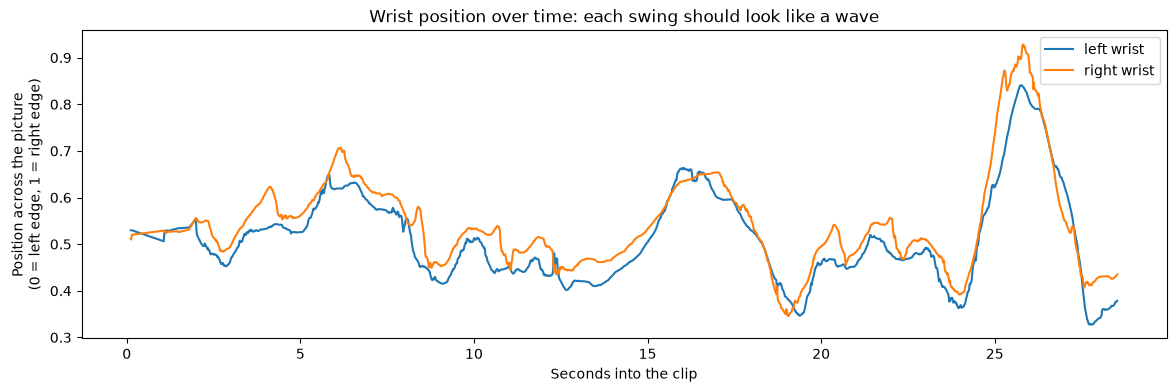

In [21]:
fig, ax = plt.subplots(figsize=(14, 4))
for point in ["left_wrist", "right_wrist"]:
    d = df[df["point"] == point]
    ax.plot(d["time_s"], d["x"], label=point.replace("_", " "))
ax.set_xlabel("Seconds into the clip")
ax.set_ylabel("Position across the picture\n(0 = left edge, 1 = right edge)")
ax.set_title("Wrist position over time: each swing should look like a wave")
ax.legend()
plt.show()

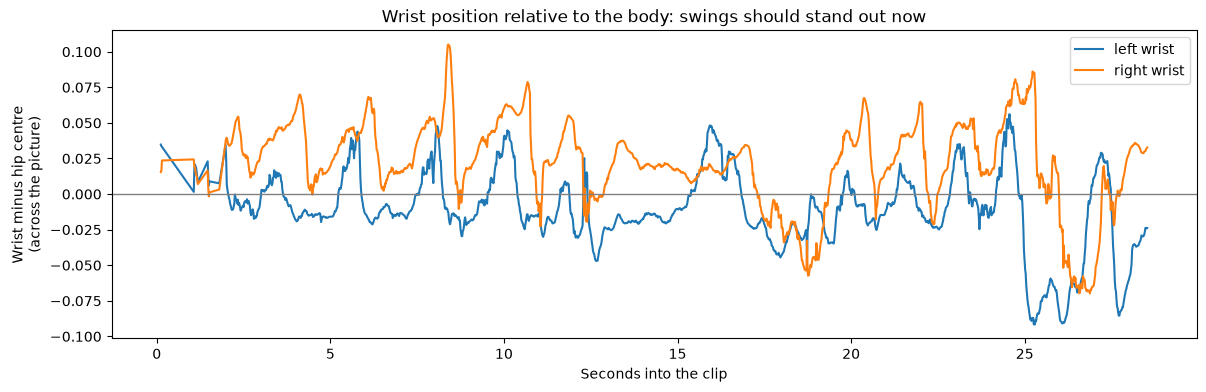

In [22]:
# Middle of the hips on each frame
hips = (df[df["point"].isin(["left_hip", "right_hip"])]
        .groupby("frame")[["x", "time_s"]].mean())

fig, ax = plt.subplots(figsize=(14, 4))
for point in ["left_wrist", "right_wrist"]:
    d = df[df["point"] == point].set_index("frame")
    relative = d["x"] - hips["x"]          # wrist position compared to the hips
    ax.plot(d["time_s"], relative, label=point.replace("_", " "))
ax.axhline(0, color="grey", linewidth=1)   # 0 = wrist directly in line with the hips
ax.set_xlabel("Seconds into the clip")
ax.set_ylabel("Wrist minus hip centre\n(across the picture)")
ax.set_title("Wrist position relative to the body: swings should stand out now")
ax.legend()
plt.show()

In [25]:
import sys, cv2
print(sys.executable)
print(cv2.__version__)


/Users/kelechiejieke/Downloads/Programming/ai-tennis-coach/.venv/bin/python
5.0.0


In [30]:
STROKES_PATH = PROJECT / "data" / "labels" / "strokes_IMG_1188.csv"
strokes = pd.read_csv(STROKES_PATH, skipinitialspace=True)
# ---- Knobs you can tune ----
WINDOW_S = 0.3              # how far before/after each logged shot to look (seconds)
SPIKE_THRESHOLD = 0.04      # how far from the hips the wrist must swing to count
RACKET_WRIST = "right_wrist"
# ----------------------------

# Wrist position relative to the middle of the hips, on every frame
hips_x = df[df["point"].isin(["left_hip", "right_hip"])].groupby("frame")["x"].mean()
wrist = df[df["point"] == RACKET_WRIST].set_index("frame")
wrist["rel"] = wrist["x"] - hips_x

results = []
for _, shot in strokes.iterrows():
    # All frames within WINDOW_S seconds of this shot
    near = wrist[(wrist["time_s"] - shot["time_s"]).abs() <= WINDOW_S]
    if near.empty:
        results.append({"time_s": shot["time_s"], "type": shot["type"],
                        "peak": None, "caught": False, "guess": None})
        continue

    # The biggest swing away from the body in that window (up or down)
    peak = near.loc[near["rel"].abs().idxmax(), "rel"]
    results.append({
        "time_s": shot["time_s"],
        "type": shot["type"],
        "peak": round(peak, 3),
        "caught": abs(peak) >= SPIKE_THRESHOLD,
        "guess": "forehand" if peak > 0 else "backhand",   # up = forehand, down = backhand
    })

check = pd.DataFrame(results)
caught = check["caught"].sum()
right_type = (check["caught"] & (check["guess"] == check["type"])).sum()
print(f"Shots caught:      {caught} of {len(check)}")
print(f"Type guessed right: {right_type} of {caught} caught shots")
check

Shots caught:      10 of 11
Type guessed right: 10 of 10 caught shots


,time_s,type,peak,caught,guess
0,0.88,forehand,0.024,False,forehand
1,2.25,forehand,0.054,True,forehand
2,4.15,forehand,0.070,True,forehand
3,6.18,forehand,0.068,True,forehand
4,8.45,forehand,0.105,True,forehand
5,10.71,forehand,0.079,True,forehand
6,18.68,backhand,-0.057,True,backhand
7,20.41,forehand,0.067,True,forehand
8,22.01,forehand,0.065,True,forehand
9,23.48,forehand,0.053,True,forehand
